# Clasificador de Frutas Frescas vs Podridas con una CNN (PyTorch)
### Proyecto final — Inteligencia Artificial (Deep Learning)
### Autor: _(tu nombre)_
---
**Problema:** dada una foto de una fruta, decidir **qué fruta es** (manzana, banana o naranja) y **si está fresca o podrida**. Son **6 clases**:

| Fresca | Podrida |
|---|---|
| `freshapples` (manzana fresca) | `rottenapples` (manzana podrida) |
| `freshbanana` (banana fresca) | `rottenbanana` (banana podrida) |
| `freshoranges` (naranja fresca) | `rottenoranges` (naranja podrida) |

**Dataset:** *Fruits fresh and rotten for classification* (Kaggle). Son 13,599 imágenes: 10,901 de train y 2,698 de test.

**Caso de uso:** control de calidad en mercados o en plantas de empaque (*packing*). Una cámara fotografía la fruta y el modelo decide si se **vende** o se **descarta**.

**Qué hacemos en este notebook** (los mismos pasos que el Assignment 4 del maestro, más algunas mejoras):
1. Importar librerías y elegir la GPU
2. Hiperparámetros
3. Transforms (preprocesamiento + data augmentation)
4. Datasets y DataLoaders (train / validación / test)
5. Visualizar un batch
6. Definir la CNN (`Net`)
7. Loss y optimizador
8. Entrenamiento con validación
9. Curvas de loss y accuracy
10. Evaluación en test (accuracy, reporte por clase, matriz de confusión)
11. Predicciones visuales
12. Análisis de errores
13. (Opcional) ¿Qué ve la CNN?
14. Predicción con fotos propias
15. Guardar el modelo
16. Respuestas a las preguntas del assignment
17. Conclusiones

## 1. Importar librerías

Usamos **PyTorch** para construir y entrenar la red, **torchvision** para cargar las imágenes y transformarlas, y **matplotlib/seaborn** para los gráficos. De **scikit-learn** sacamos las métricas (accuracy, matriz de confusión y reporte por clase).

Además hacemos dos cosas que el maestro no hace:
- **Usar la GPU** (`cuda`). Una GPU hace miles de multiplicaciones en paralelo, y entrenar una CNN es justamente eso: multiplicar matrices. En la RTX 4070 entrena decenas de veces más rápido que en CPU.
- **Fijar semillas** para que los números aleatorios (la mezcla de los datos y los pesos iniciales) salgan iguales en cada ejecución. Así los resultados se pueden reproducir.

In [1]:
import sys  # Para agregar la raíz del proyecto al path de Python e importar src/modelo.py
import time  # Para medir cuánto tarda cada epoch
import copy  # Para hacer una copia "profunda" (independiente) de los pesos del mejor modelo
import json  # Para guardar la configuración del modelo (clases, tamaño, normalización)
import random  # Para elegir imágenes al azar y fijar la semilla de Python
from pathlib import Path  # Para manejar rutas de archivos de forma cómoda (funciona en Windows y Linux)

import numpy as np  # Operaciones numéricas con arrays
import matplotlib.pyplot as plt  # Gráficos: imágenes y curvas de entrenamiento
import seaborn as sns  # Gráficos estadísticos; lo usamos para la matriz de confusión (heatmap)
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # Métricas de evaluación
from PIL import Image, ImageOps  # Para abrir fotos propias y corregir su orientación (EXIF del celular)

import torch  # Librería principal de PyTorch: tensores, GPU y gradientes automáticos (autograd)
import torchvision  # Datasets, modelos y utilidades para visión por computadora
import torchvision.transforms as transforms  # Preprocesamiento y data augmentation de imágenes
import torch.nn as nn  # Capas de redes neuronales y funciones de pérdida
import torch.nn.functional as F  # Funciones sin parámetros: relu, softmax, etc.
from torch.utils.data import Subset, DataLoader  # Subset: un "pedazo" de un dataset. DataLoader: entrega los datos en batches

# ---- Dispositivo: GPU si existe, si no CPU ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # El maestro entrena en CPU; nosotros usamos la GPU
print("PyTorch:", torch.__version__)  # Versión de PyTorch instalada
print("Dispositivo:", device)  # Muestra si estamos usando "cuda" (GPU) o "cpu"
if device.type == "cuda":  # Solo si hay GPU...
    print("GPU:", torch.cuda.get_device_name(0))  # ...mostramos su nombre

# ---- Semillas: para que los resultados sean reproducibles ----
SEMILLA = 42  # Cualquier número fijo sirve; 42 es una convención
random.seed(SEMILLA)  # Semilla del módulo random de Python
np.random.seed(SEMILLA)  # Semilla de NumPy
torch.manual_seed(SEMILLA)  # Semilla de PyTorch (afecta los pesos iniciales y el orden de los batches)

# ---- Rutas del proyecto ----
RAIZ = Path("..")  # El notebook vive en notebooks/, así que la raíz del proyecto está un nivel arriba
DATA_DIR = RAIZ / "data"  # Dataset: data/train y data/test
MODELS_DIR = RAIZ / "models"  # Aquí guardamos los pesos del modelo y el config.json
OUTPUTS_DIR = RAIZ / "outputs"  # Aquí guardamos las figuras (curvas, matriz de confusión, etc.)
MODELS_DIR.mkdir(exist_ok=True)  # Crea la carpeta si no existe
OUTPUTS_DIR.mkdir(exist_ok=True)  # Crea la carpeta si no existe

PyTorch: 2.14.1+cu130
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


## 2. Hiperparámetros

Los **hiperparámetros** son los valores que elegimos **nosotros** antes de entrenar. Los **parámetros** (pesos), en cambio, los aprende la red sola. Los ponemos todos en una celda para poder cambiarlos fácilmente y experimentar.

- **Learning rate (LR):** qué tan grande es cada paso al corregir los pesos. Si es muy grande, el entrenamiento "salta" y no converge; si es muy chico, aprende lentísimo.
- **Batch size:** cuántas imágenes procesa la red antes de actualizar los pesos una vez.
- **Epoch:** una pasada completa por todas las imágenes de entrenamiento.
- `QUICK_RUN=True` sirve para comprobar en segundos que todo el notebook corre sin errores (usa ~500 imágenes y 1 epoch). **Para el entrenamiento real va en `False`.**

In [2]:
IMG_SIZE = 128      # Alto y ancho al que se redimensiona cada imagen (128x128, igual que el maestro)
BATCH_SIZE = 64     # Imágenes por batch. El maestro usa 32; la RTX 4070 aguanta 64 (si sale "CUDA out of memory", bajar a 32)
LR = 0.001          # Learning rate del optimizador Adam (igual que el maestro)
N_EPOCHS = 20       # Cuántas veces la red ve TODO el set de entrenamiento (igual que el maestro)
VAL_SPLIT = 0.15    # Fracción de train que separamos como validación (15%)
NUM_WORKERS = 4     # Procesos que cargan imágenes en paralelo mientras la GPU entrena. Si Jupyter se cuelga en Windows, poner 0
QUICK_RUN = False   # True = prueba rápida (~500 imágenes, 1 epoch). False = entrenamiento completo

if QUICK_RUN:  # En modo prueba...
    N_EPOCHS = 1  # ...entrenamos solo 1 epoch
    print("QUICK_RUN activado: pocas imágenes y 1 epoch. Los resultados NO son representativos.")

## 3. Transforms (preprocesamiento y data augmentation)

Una red neuronal no entiende archivos `.png`: necesita **tensores** de números de tamaño fijo. Los *transforms* convierten cada imagen:
1. `Resize((128,128))`: todas al mismo tamaño, porque la red espera siempre la misma forma de entrada.
2. `ToTensor()`: convierte la imagen en un tensor de forma `(3, 128, 128)` (canales RGB × alto × ancho) con valores entre 0 y 1.
3. `Normalize(mean=0.5, std=0.5)`: aplica `(x - 0.5) / 0.5` y lleva los valores a **[-1, 1]**. Con datos centrados en 0 la red entrena más estable.

**Data augmentation (solo en train):** al azar volteamos la imagen horizontalmente, la rotamos hasta 10° y cambiamos un poco el brillo y el contraste. Cada epoch la red ve versiones algo distintas de la misma foto, así que le cuesta más "memorizar" y aprende a **generalizar**. En test **no** se aplica augmentation: queremos evaluar las imágenes tal cual son.

In [3]:
MEAN = (0.5, 0.5, 0.5)  # Media por canal (R, G, B) que se resta al normalizar
STD = (0.5, 0.5, 0.5)   # Desviación estándar por canal por la que se divide

# Transformaciones de ENTRENAMIENTO (con data augmentation)
train_transform = transforms.Compose([  # Compose aplica la lista de transformaciones en orden
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # Redimensiona a 128x128 píxeles
    transforms.RandomHorizontalFlip(),  # Voltea horizontalmente con probabilidad 50% (una manzana volteada sigue siendo manzana)
    transforms.RandomRotation(10),  # Rota al azar entre -10° y +10°
    transforms.ColorJitter(brightness=0.2, contrast=0.2),  # (Opcional) Varía brillo y contraste ±20% para simular otra iluminación.
                                                           # NO tocamos el tono (hue): el color marrón/verde es clave para detectar lo podrido
    transforms.ToTensor(),  # Convierte la imagen PIL a tensor (C, H, W) con valores en [0, 1]
    transforms.Normalize(MEAN, STD),  # (x - 0.5) / 0.5  ->  valores en [-1, 1]
])

# Transformaciones de TEST y VALIDACIÓN (sin augmentation: evaluamos la imagen tal cual)
test_transform = transforms.Compose([  # Mismos pasos de preprocesamiento, sin los aleatorios
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # Mismo tamaño que en entrenamiento
    transforms.ToTensor(),  # A tensor en [0, 1]
    transforms.Normalize(MEAN, STD),  # Misma normalización que en entrenamiento (¡tiene que ser idéntica!)
])

## 4. Datasets y DataLoaders: train / validación / test

`ImageFolder` asume que **cada subcarpeta es una clase** (`data/train/freshapples/...`) y le asigna un número a cada clase en **orden alfabético**.

El maestro usa solo train y test. Nosotros separamos además un **15% de train como validación**:
- **Train:** la red aprende con estas imágenes (ajusta sus pesos).
- **Validación:** después de cada epoch medimos con ellas cómo va la red y elegimos **el mejor epoch**. La red **nunca** aprende de estas imágenes.
- **Test:** se usan **una sola vez, al final**, para la nota honesta. Si usáramos test para elegir el mejor epoch, estaríamos "haciendo trampa" sin querer.

Truco: creamos **dos vistas** de la carpeta train, una **con** augmentation (para entrenar) y otra **sin** augmentation (para validar), y repartimos los índices entre ellas.

El **DataLoader** entrega las imágenes en batches, las mezcla (`shuffle`) en cada epoch y las carga en paralelo con varios procesos (`num_workers`).

In [4]:
# Dos "vistas" de la MISMA carpeta train: una con augmentation (para entrenar) y otra sin augmentation (para validar)
full_train_aug = torchvision.datasets.ImageFolder(DATA_DIR / "train", transform=train_transform)
full_train_eval = torchvision.datasets.ImageFolder(DATA_DIR / "train", transform=test_transform)
test_dataset = torchvision.datasets.ImageFolder(DATA_DIR / "test", transform=test_transform)  # El test, sin augmentation

clases = full_train_aug.classes  # Nombres de las clases (carpetas), en orden alfabético: el índice 0 es la primera, etc.
NOMBRES_ES = {  # Traducción al español para mostrar en gráficos y en la app
    "freshapples": "Manzana fresca", "freshbanana": "Banana fresca", "freshoranges": "Naranja fresca",
    "rottenapples": "Manzana podrida", "rottenbanana": "Banana podrida", "rottenoranges": "Naranja podrida",
}
nombres = [NOMBRES_ES[c] for c in clases]  # Lista de nombres en español, en el mismo orden que los índices
print("Clases (índice -> carpeta):", dict(enumerate(clases)))

# Mezclamos los índices con una semilla fija para que el split train/validación sea siempre el mismo
g = torch.Generator().manual_seed(SEMILLA)  # Generador de números aleatorios con semilla propia
indices = torch.randperm(len(full_train_aug), generator=g).tolist()  # Permutación aleatoria de 0..N-1
n_val = int(len(indices) * VAL_SPLIT)  # Cantidad de imágenes para validación (15%)
val_idx, train_idx = indices[:n_val], indices[n_val:]  # Los primeros n_val van a validación y el resto a train

if QUICK_RUN:  # Modo prueba rápida: nos quedamos con pocas imágenes
    train_idx, val_idx = train_idx[:400], val_idx[:100]

train_dataset = Subset(full_train_aug, train_idx)  # Train: vista CON augmentation, solo con los índices de train
val_dataset = Subset(full_train_eval, val_idx)  # Validación: vista SIN augmentation, solo con los índices de validación

# Opciones comunes de los DataLoaders
loader_kwargs = dict(
    batch_size=BATCH_SIZE,  # Imágenes por batch
    num_workers=NUM_WORKERS,  # Procesos que leen y transforman las imágenes en paralelo
    pin_memory=(device.type == "cuda"),  # Memoria "fija" que acelera la copia de CPU a GPU
    persistent_workers=(NUM_WORKERS > 0),  # No vuelve a crear los procesos en cada epoch (en Windows crearlos es lento)
)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)  # shuffle=True: orden distinto en cada epoch
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)  # Validación sin mezclar (el orden no importa)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)  # Test sin mezclar, para poder ubicar cada predicción

print(f"Train: {len(train_dataset)} imágenes | Validación: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Batches por epoch (train): {len(train_loader)}")

Clases (índice -> carpeta): {0: 'freshapples', 1: 'freshbanana', 2: 'freshoranges', 3: 'rottenapples', 4: 'rottenbanana', 5: 'rottenoranges'}
Train: 9266 imágenes | Validación: 1635 | Test: 2698
Batches por epoch (train): 145


> **Ojo con este dataset (fuga de datos o *data leakage*).** Revisando los nombres de los archivos se ve que solo ~11% son fotos "originales". El resto son **copias aumentadas** que el autor del dataset ya creó: `rotated_by_15_…`, `rotated_by_30_…` (hasta 75°), `translation_…`, `vertical_flip_…` y `saltandpepper_…` (ruido). Además, **las 2,698 imágenes de test tienen el mismo nombre base que alguna imagen de train**: el test contiene versiones rotadas o volteadas de fotos que la red ya vio al entrenar. Lo mismo pasa entre nuestro train y nuestra validación.
>
> **Consecuencia:** la accuracy en test (y en validación) va a salir **optimista**. Mide qué tan bien reconoce variantes de fotos conocidas, no fotos totalmente nuevas. La prueba más honesta es la de la **sección 14, con fotos propias**. Es un buen punto para la defensa: *un número alto no sirve si los datos de test no son independientes de los de entrenamiento.*

## 5. Visualizar un batch

Antes de entrenar **siempre** hay que mirar los datos: ¿se cargaron bien?, ¿las etiquetas corresponden a la imagen?, ¿el augmentation se ve razonable?

Como las imágenes están normalizadas en [-1, 1], para mostrarlas hay que **desnormalizar**: `x * 0.5 + 0.5` (lo mismo que `x / 2 + 0.5` del maestro) las devuelve a [0, 1]. `make_grid` arma una cuadrícula con varias imágenes.

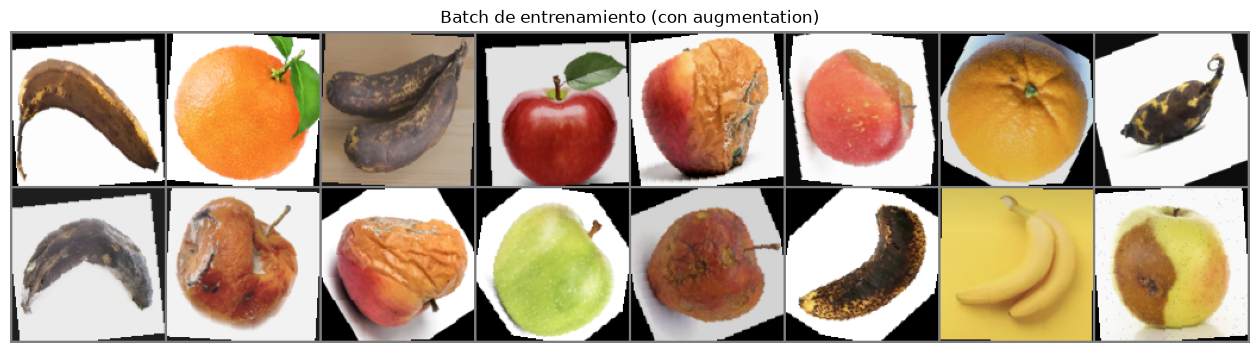

 Banana podrida |  Naranja fresca |  Banana podrida |  Manzana fresca | Manzana podrida | Manzana podrida |  Naranja fresca |  Banana podrida
 Banana podrida | Manzana podrida | Manzana podrida |  Manzana fresca | Manzana podrida |  Banana podrida |   Banana fresca | Manzana podrida


In [5]:
def imshow(img, titulo=None):
    """Función del maestro: desnormaliza un tensor (C, H, W) y lo muestra con matplotlib."""
    img = img / 2 + 0.5  # Desnormaliza: de [-1, 1] vuelve a [0, 1]
    npimg = img.clamp(0, 1).numpy()  # A NumPy (clamp evita valores apenas fuera de [0, 1] por redondeo)
    plt.figure(figsize=(16, 5))  # Figura ancha para la cuadrícula
    plt.imshow(np.transpose(npimg, (1, 2, 0)))  # PyTorch usa (C, H, W) y matplotlib (H, W, C): reordenamos los ejes
    plt.axis("off")  # Sin ejes
    if titulo:  # Si nos pasan un título...
        plt.title(titulo)  # ...lo ponemos
    plt.show()  # Muestra la figura

def desnormalizar(img):
    """Convierte UN tensor normalizado (C, H, W) en un array (H, W, C) en [0, 1], listo para plt.imshow."""
    return (img.cpu() * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()  # Desnormaliza, recorta y reordena los ejes

images, labels = next(iter(train_loader))  # Toma el primer batch del train_loader (ya con augmentation)
imshow(torchvision.utils.make_grid(images[:16], nrow=8), "Batch de entrenamiento (con augmentation)")  # 16 imágenes en 2 filas de 8
for fila in range(2):  # Imprime las etiquetas en el mismo orden que la cuadrícula
    print(" | ".join(f"{nombres[labels[j]]:>15}" for j in range(fila * 8, fila * 8 + 8)))

## 6. Definir la CNN (`Net`)

Es la misma arquitectura del maestro, pero con **6 salidas** en lugar de 2. Tiene **3 bloques convolucionales** y luego una parte **fully connected**:

```
Entrada (3, 128, 128)
 → Conv 3x3 (32 filtros) → BatchNorm → ReLU → MaxPool 2x2  → (32, 64, 64)
 → Conv 3x3 (64 filtros) → BatchNorm → ReLU → MaxPool 2x2  → (64, 32, 32)
 → Conv 3x3 (128 filtros)→ BatchNorm → ReLU → MaxPool 2x2  → (128, 16, 16)
 → Aplanar (128·16·16 = 32,768) → Dropout
 → Linear 32768→512 → BatchNorm → ReLU → Dropout
 → Linear 512→6  (logits: un puntaje por clase)
```

- **Convolución:** un filtro de 3x3 recorre la imagen y responde fuerte donde encuentra "su" patrón (un borde, una mancha, una textura). Las primeras capas detectan cosas simples y las más profundas combinan esas cosas en patrones complejos (la textura de una cáscara podrida, por ejemplo).
- **`padding=1`:** agrega un borde de 1 píxel para que la convolución no achique la imagen (128 → 128).
- **MaxPool 2x2:** de cada cuadrito de 2x2 se queda con el valor mayor. Reduce el ancho y el alto a la mitad (menos cómputo) y da algo de tolerancia a pequeños desplazamientos.
- **BatchNorm:** normaliza las activaciones de cada batch; el entrenamiento es más estable y más rápido.
- **ReLU:** `max(0, x)`. Es la no linealidad: sin ella, apilar capas sería igual que tener una sola capa lineal.
- **Dropout(0.25):** durante el entrenamiento "apaga" al azar el 25% de las neuronas, así la red no depende de unas pocas y sobreajusta menos.

Usamos `%%writefile` para que esta misma celda **guarde la clase en `src/modelo.py`**. Así la app y el script de predicción usan **exactamente** la misma arquitectura.

In [6]:
%%writefile ../src/modelo.py
# =====================================================================
# src/modelo.py — Arquitectura de la CNN.
# Este archivo se GENERA desde notebooks/01_frutas_cnn.ipynb (celda con %%writefile).
# Si quieres cambiar la red, cámbiala en el notebook y vuelve a ejecutar esa celda.
# =====================================================================
import torch.nn as nn  # Capas de redes neuronales
import torch.nn.functional as F  # Funciones sin parámetros (relu)


class Net(nn.Module):
    """CNN del maestro (Assignment 4) adaptada a n_clases. Entrada: imágenes RGB de 128x128."""

    def __init__(self, n_clases=6):
        super().__init__()  # Inicializa la clase padre nn.Module (obligatorio)

        # ---- Bloques convolucionales con BatchNorm ----
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)  # 3 canales de entrada (RGB) -> 32 filtros de 3x3; padding=1 mantiene 128x128
        self.bn1 = nn.BatchNorm2d(32)  # Normaliza los 32 mapas que salen de conv1
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)  # 32 -> 64 filtros
        self.bn2 = nn.BatchNorm2d(64)  # Normaliza los 64 mapas de conv2
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)  # 64 -> 128 filtros
        self.bn3 = nn.BatchNorm2d(128)  # Normaliza los 128 mapas de conv3
        self.pool = nn.MaxPool2d(2, 2)  # Max pooling 2x2 con paso 2: reduce alto y ancho a la mitad
        self.dropout = nn.Dropout(0.25)  # Apaga al azar el 25% de las neuronas (solo en entrenamiento)

        # ---- Parte fully connected ----
        # Con entrada de 128x128 y 3 poolings: 128 -> 64 -> 32 -> 16. Salen 128 mapas de 16x16.
        self.fc1 = nn.Linear(128 * 16 * 16, 512)  # 32,768 entradas -> 512 neuronas (¡aquí está la mayoría de los parámetros!)
        self.bn_fc = nn.BatchNorm1d(512)  # Normaliza las 512 salidas de fc1
        self.fc2 = nn.Linear(512, n_clases)  # Capa de salida: un puntaje (logit) por clase

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))  # Bloque 1: conv -> BN -> ReLU -> pool   (3,128,128) -> (32,64,64)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))  # Bloque 2                               -> (64,32,32)
        x = self.pool(F.relu(self.bn3(self.conv3(x))))  # Bloque 3                               -> (128,16,16)
        x = x.view(x.size(0), -1)  # Aplanar: (batch, 128, 16, 16) -> (batch, 32768)
        x = self.dropout(x)  # Dropout antes de la capa densa
        x = F.relu(self.bn_fc(self.fc1(x)))  # fc1 -> BN -> ReLU
        x = self.dropout(x)  # Dropout otra vez
        return self.fc2(x)  # Logits (SIN softmax: CrossEntropyLoss ya lo aplica internamente)

Overwriting ../src/modelo.py


In [7]:
sys.path.append(str(RAIZ.resolve()))  # Agrega la raíz del proyecto al path para que funcione "from src.modelo import Net"
from src.modelo import Net  # Importa la clase que acabamos de escribir en src/modelo.py

net = Net(n_clases=len(clases)).to(device)  # Crea la red con 6 salidas y la mueve a la GPU
print(net)  # Muestra las capas

# ---- ¿Cuántos parámetros (pesos) tiene la red? ----
n_total = sum(p.numel() for p in net.parameters())  # numel() = número de elementos de cada tensor de pesos
n_fc1 = sum(p.numel() for p in net.fc1.parameters())  # Solo los de fc1
print(f"\nParámetros totales: {n_total:,}")
print(f"Parámetros en fc1:  {n_fc1:,}  ({100 * n_fc1 / n_total:.1f}% del total)")

# ---- Recorrido de una imagen por la red: cómo cambia la forma del tensor ----
net.eval()  # Modo evaluación (BatchNorm1d no acepta un batch de 1 imagen en modo entrenamiento)
with torch.no_grad():  # No necesitamos gradientes para esto
    x = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=device)  # Una "imagen" falsa de 1x3x128x128
    print("\nEntrada:            ", tuple(x.shape))
    for i, (conv, bn) in enumerate([(net.conv1, net.bn1), (net.conv2, net.bn2), (net.conv3, net.bn3)], start=1):
        x = net.pool(F.relu(bn(conv(x))))  # Aplica un bloque convolucional
        print(f"Después del bloque {i}:", tuple(x.shape))
    print("Aplanado:           ", tuple(x.view(1, -1).shape))

Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=32768, out_features=512, bias=True)
  (bn_fc): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=512, out_features=6, bias=True)
)

Parámetros totales: 16,875,526
Parámetros en fc1:  16,777,728  (99.4% del total)

Entrada:             (

Después del bloque 2:

 (1, 64, 32, 32)
Después del bloque 3: (1, 128, 16, 16)
Aplanado:            (1, 32768)


**Observación importante:** casi todos los parámetros (~16.8 de ~16.9 millones) están en **`fc1`**, porque conecta **32,768** entradas con 512 neuronas: 32,768 × 512 ≈ 16.8M pesos. Las capas convolucionales tienen muy pocos parámetros porque **comparten** el mismo filtro de 3x3 en todas las posiciones de la imagen. Por eso el `.pth` pesa ~68 MB (cada parámetro es un float de 4 bytes). Esto también es una pista de **cómo mejorar** el modelo (ver la sección 16).

## 7. Función de pérdida y optimizador

- **`CrossEntropyLoss`:** es la pérdida estándar para clasificación con varias clases. Internamente aplica **softmax** a los logits (los convierte en probabilidades que suman 1) y luego calcula `-log(probabilidad de la clase correcta)`. Si la red le da 0.95 a la clase correcta, la pérdida es baja (0.05); si le da 0.05, es alta (3.0).
- **Adam (`lr=0.001`):** el optimizador decide cómo mover cada peso a partir de su gradiente. Es una versión mejorada del descenso de gradiente: tiene *momentum* (recuerda la dirección en la que venía) y ajusta un learning rate propio para cada peso.

In [8]:
criterion = nn.CrossEntropyLoss()  # Pérdida para clasificación multiclase (softmax + log-loss en una sola función)
optimizer = torch.optim.Adam(net.parameters(), lr=LR)  # Adam actualiza TODOS los parámetros de la red con lr=0.001

## 8. Entrenamiento (con validación en cada epoch)

Es el mismo loop del maestro. Para **cada batch**:
1. `optimizer.zero_grad()`: borra los gradientes del batch anterior (PyTorch los acumula si no se borran).
2. `outputs = net(inputs)`: **forward**, la red predice.
3. `loss = criterion(outputs, labels)`: medimos qué tan mal predijo.
4. `loss.backward()`: **backpropagation**, calcula cuánto contribuyó cada peso al error (el gradiente).
5. `optimizer.step()`: mueve cada peso un poquito en la dirección que reduce el error.

**Lo que agregamos al loop del maestro:** al final de cada epoch evaluamos en **validación** (con `net.eval()` y `torch.no_grad()`), guardamos el historial para graficarlo y nos quedamos con los **pesos del epoch con mejor accuracy de validación**. Si la red empieza a sobreajustar en los últimos epochs, igual conservamos el mejor momento.

`net.train()` y `net.eval()` importan: en modo entrenamiento el Dropout apaga neuronas y BatchNorm usa las estadísticas del batch; en modo evaluación el Dropout se desactiva y BatchNorm usa las estadísticas acumuladas.

In [9]:
historial = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}  # Para graficar las curvas después
mejor_acc, mejores_pesos, mejor_epoch = 0.0, None, 0  # Para recordar el mejor modelo según validación

t_inicio = time.time()  # Para medir el tiempo total de entrenamiento
for epoch in range(N_EPOCHS):  # Una iteración = una pasada completa por el set de entrenamiento
    t0 = time.time()  # Tiempo de inicio de este epoch

    # ---------------- ENTRENAMIENTO ----------------
    net.train()  # Modo entrenamiento: activa Dropout y BatchNorm usa las estadísticas del batch
    running_loss, correctos, total = 0.0, 0, 0  # Acumuladores del epoch
    for inputs, labels in train_loader:  # Recorre el set de train de a un batch
        inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)  # Mueve el batch a la GPU
        optimizer.zero_grad()  # 1. Borra los gradientes del batch anterior
        outputs = net(inputs)  # 2. Forward: la red produce logits de forma (batch, 6)
        loss = criterion(outputs, labels)  # 3. Calcula la pérdida comparando con las etiquetas reales
        loss.backward()  # 4. Backpropagation: calcula el gradiente de la pérdida respecto a cada peso
        optimizer.step()  # 5. Actualiza los pesos usando esos gradientes
        running_loss += loss.item() * inputs.size(0)  # loss es el promedio del batch; multiplicamos para sumar la pérdida total
        correctos += (outputs.argmax(1) == labels).sum().item()  # argmax(1) = clase con mayor puntaje; contamos aciertos
        total += labels.size(0)  # Cantidad de imágenes vistas
    train_loss, train_acc = running_loss / total, correctos / total  # Promedios del epoch

    # ---------------- VALIDACIÓN ----------------
    net.eval()  # Modo evaluación: desactiva Dropout y BatchNorm usa las estadísticas acumuladas
    running_loss, correctos, total = 0.0, 0, 0  # Reiniciamos los acumuladores
    with torch.no_grad():  # Sin gradientes: más rápido y usa menos memoria (aquí no aprendemos)
        for inputs, labels in val_loader:  # Recorre la validación
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            outputs = net(inputs)  # Solo forward
            running_loss += criterion(outputs, labels).item() * inputs.size(0)  # Suma la pérdida
            correctos += (outputs.argmax(1) == labels).sum().item()  # Suma los aciertos
            total += labels.size(0)
    val_loss, val_acc = running_loss / total, correctos / total  # Promedios de validación

    for k, v in zip(historial, [train_loss, train_acc, val_loss, val_acc]):  # Guarda las 4 métricas en el historial
        historial[k].append(v)

    # ---- Guardar el mejor modelo según la accuracy de validación ----
    marca = ""  # Para marcar en el print los epochs que mejoran
    if val_acc > mejor_acc:  # ¿Este epoch es el mejor hasta ahora?
        mejor_acc, mejor_epoch = val_acc, epoch + 1  # Recordamos la accuracy y el epoch
        mejores_pesos = copy.deepcopy(net.state_dict())  # Copia independiente de los pesos (si no, se sobrescribirían)
        marca = "  <- mejor"

    print(f"Epoch [{epoch+1:2d}/{N_EPOCHS}] train_loss={train_loss:.3f} train_acc={train_acc:.3f} "
          f"| val_loss={val_loss:.3f} val_acc={val_acc:.3f} | {time.time()-t0:.1f}s{marca}")

tiempo_entrenamiento = time.time() - t_inicio  # Tiempo total en segundos
net.load_state_dict(mejores_pesos)  # Nos quedamos con los pesos del MEJOR epoch, no necesariamente el último
print(f"\nEntrenamiento terminado en {tiempo_entrenamiento/60:.1f} min. "
      f"Mejor val_acc = {mejor_acc:.3f} (epoch {mejor_epoch}).")

Epoch [ 1/20] train_loss=0.412 train_acc=0.853 | val_loss=0.350 val_acc=0.870 | 38.3s  <- mejor


Epoch [ 2/20] train_loss=0.225 train_acc=0.919 | val_loss=0.184 val_acc=0.931 | 7.1s  <- mejor


Epoch [ 3/20] train_loss=0.181 train_acc=0.934 | val_loss=0.216 val_acc=0.931 | 7.2s


Epoch [ 4/20] train_loss=0.151 train_acc=0.946 | val_loss=0.095 val_acc=0.963 | 7.3s  <- mejor


Epoch [ 5/20] train_loss=0.123 train_acc=0.956 | val_loss=0.193 val_acc=0.927 | 7.5s


...

Epoch [16/20] train_loss=0.040 train_acc=0.986 | val_loss=0.039 val_acc=0.987 | 7.6s


Epoch [17/20] train_loss=0.034 train_acc=0.990 | val_loss=0.029 val_acc=0.990 | 7.6s


Epoch [18/20] train_loss=0.026 train_acc=0.991 | val_loss=0.044 val_acc=0.986 | 7.5s


Epoch [19/20] train_loss=0.027 train_acc=0.993 | val_loss=0.040 val_acc=0.987 | 7.8s


Epoch [20/20] train_loss=0.023 train_acc=0.993 | val_loss=0.022 val_acc=0.993 | 7.5s  <- mejor

Entrenamiento terminado en 3.0 min. Mejor val_acc = 0.993 (epoch 20).


## 9. Curvas de loss y accuracy (train vs validación)

Estas curvas son la mejor herramienta para diagnosticar el entrenamiento:
- **Buen entrenamiento:** las dos losses bajan y las dos accuracies suben, cerca una de la otra.
- **Overfitting (sobreajuste):** la loss de **train sigue bajando** pero la de **validación se estanca o sube**. La red está memorizando las imágenes de train en vez de aprender patrones generales.
- **Underfitting:** ambas quedan altas; la red es muy simple o le faltan epochs.

Que la accuracy de validación a veces salga **mayor** que la de train es normal: en train hay augmentation y Dropout (la tarea es más difícil), y en validación no.

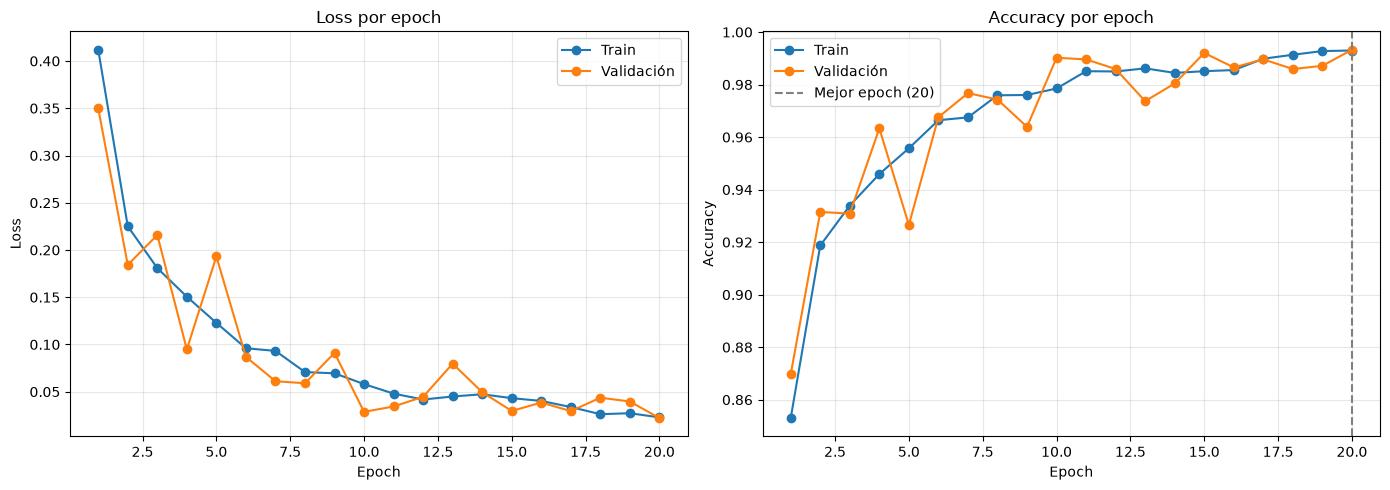

In [10]:
epochs_x = range(1, len(historial["train_loss"]) + 1)  # Eje X: 1, 2, ..., N_EPOCHS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))  # Dos gráficos lado a lado

ax1.plot(epochs_x, historial["train_loss"], "o-", label="Train")  # Loss de entrenamiento
ax1.plot(epochs_x, historial["val_loss"], "o-", label="Validación")  # Loss de validación
ax1.set_title("Loss por epoch"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs_x, historial["train_acc"], "o-", label="Train")  # Accuracy de entrenamiento
ax2.plot(epochs_x, historial["val_acc"], "o-", label="Validación")  # Accuracy de validación
ax2.axvline(mejor_epoch, color="gray", ls="--", label=f"Mejor epoch ({mejor_epoch})")  # Línea vertical en el mejor epoch
ax2.set_title("Accuracy por epoch"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()  # Ajusta los márgenes
plt.savefig(OUTPUTS_DIR / "curvas_cnn.png", dpi=120)  # Guarda la figura para el README
plt.show()

## 10. Evaluación en test

Ahora sí usamos el **test**, una sola vez y con el mejor modelo. Calculamos:
- **Accuracy:** el % de imágenes bien clasificadas.
- **`classification_report`:** por cada clase:
  - **Precision:** de las que la red llamó "X", ¿cuántas eran X de verdad?
  - **Recall:** de todas las X reales, ¿cuántas encontró la red?
  - **F1:** la media armónica de las dos; resume ambas en un solo número.
- **Matriz de confusión:** las filas son la clase real y las columnas la predicha. La diagonal son los aciertos y lo que está fuera de ella muestra **qué clases se confunden con cuáles**.

En control de calidad importa mucho el **recall de las clases podridas**: una fruta podrida que se cuela como fresca es el error más caro.

In [11]:
net.eval()  # Modo evaluación
all_preds, all_labels, all_probs = [], [], []  # Para guardar las predicciones, las etiquetas reales y las probabilidades

with torch.no_grad():  # Sin gradientes
    for inputs, labels in test_loader:  # Recorre todo el test (en orden, porque shuffle=False)
        outputs = net(inputs.to(device))  # Logits (batch, 6)
        probs = torch.softmax(outputs, dim=1)  # Softmax: convierte logits en probabilidades que suman 1
        all_probs.append(probs.cpu())  # Guardamos las probabilidades (las traemos a CPU)
        all_preds.append(probs.argmax(1).cpu())  # La clase predicha es la de mayor probabilidad
        all_labels.append(labels)  # Etiquetas reales

all_probs = torch.cat(all_probs).numpy()  # Une todos los batches: (n_test, 6)
all_preds = torch.cat(all_preds).numpy()  # (n_test,)
all_labels = torch.cat(all_labels).numpy()  # (n_test,)

accuracy = accuracy_score(all_labels, all_preds)  # % de aciertos
print(f"Accuracy en test: {accuracy * 100:.2f}%  ({(all_preds == all_labels).sum()} de {len(all_labels)} imágenes)\n")
print(classification_report(all_labels, all_preds, target_names=nombres, digits=3))  # Precision, recall y F1 por clase

Accuracy en test: 99.07%  (2673 de 2698 imágenes)

                 precision    recall  f1-score   support

 Manzana fresca      0.985     0.997     0.991       395
  Banana fresca      0.997     1.000     0.999       381
 Naranja fresca      0.995     0.987     0.991       388
Manzana podrida      0.983     0.985     0.984       601
 Banana podrida      0.998     0.996     0.997       530
Naranja podrida      0.988     0.980     0.984       403

       accuracy                          0.991      2698
      macro avg      0.991     0.991     0.991      2698
   weighted avg      0.991     0.991     0.991      2698



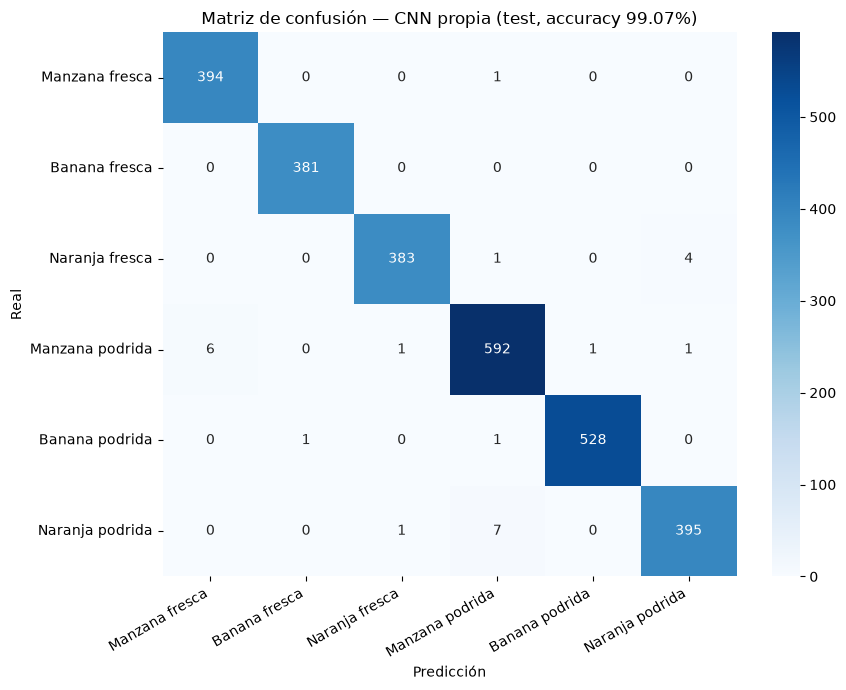

In [12]:
cm = confusion_matrix(all_labels, all_preds)  # Matriz 6x6: filas = real, columnas = predicho
plt.figure(figsize=(9, 7))  # Tamaño de la figura
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",  # annot: escribe el número en cada celda; fmt="d": enteros
            xticklabels=nombres, yticklabels=nombres)  # Nombres de las clases en los ejes
plt.xlabel("Predicción"); plt.ylabel("Real")  # Etiquetas de los ejes
plt.title(f"Matriz de confusión — CNN propia (test, accuracy {accuracy*100:.2f}%)")
plt.xticks(rotation=30, ha="right"); plt.yticks(rotation=0)  # Rota los textos para que no se encimen
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "matriz_confusion_cnn.png", dpi=120)  # Guarda la figura
plt.show()

## 11. Predicciones visuales

Como en el notebook del maestro, elegimos imágenes **al azar** del test y mostramos lo que predice la red, junto con la clase real y la **confianza** (la probabilidad que le dio softmax a la clase elegida). En **verde** van los aciertos y en **rojo** los errores.

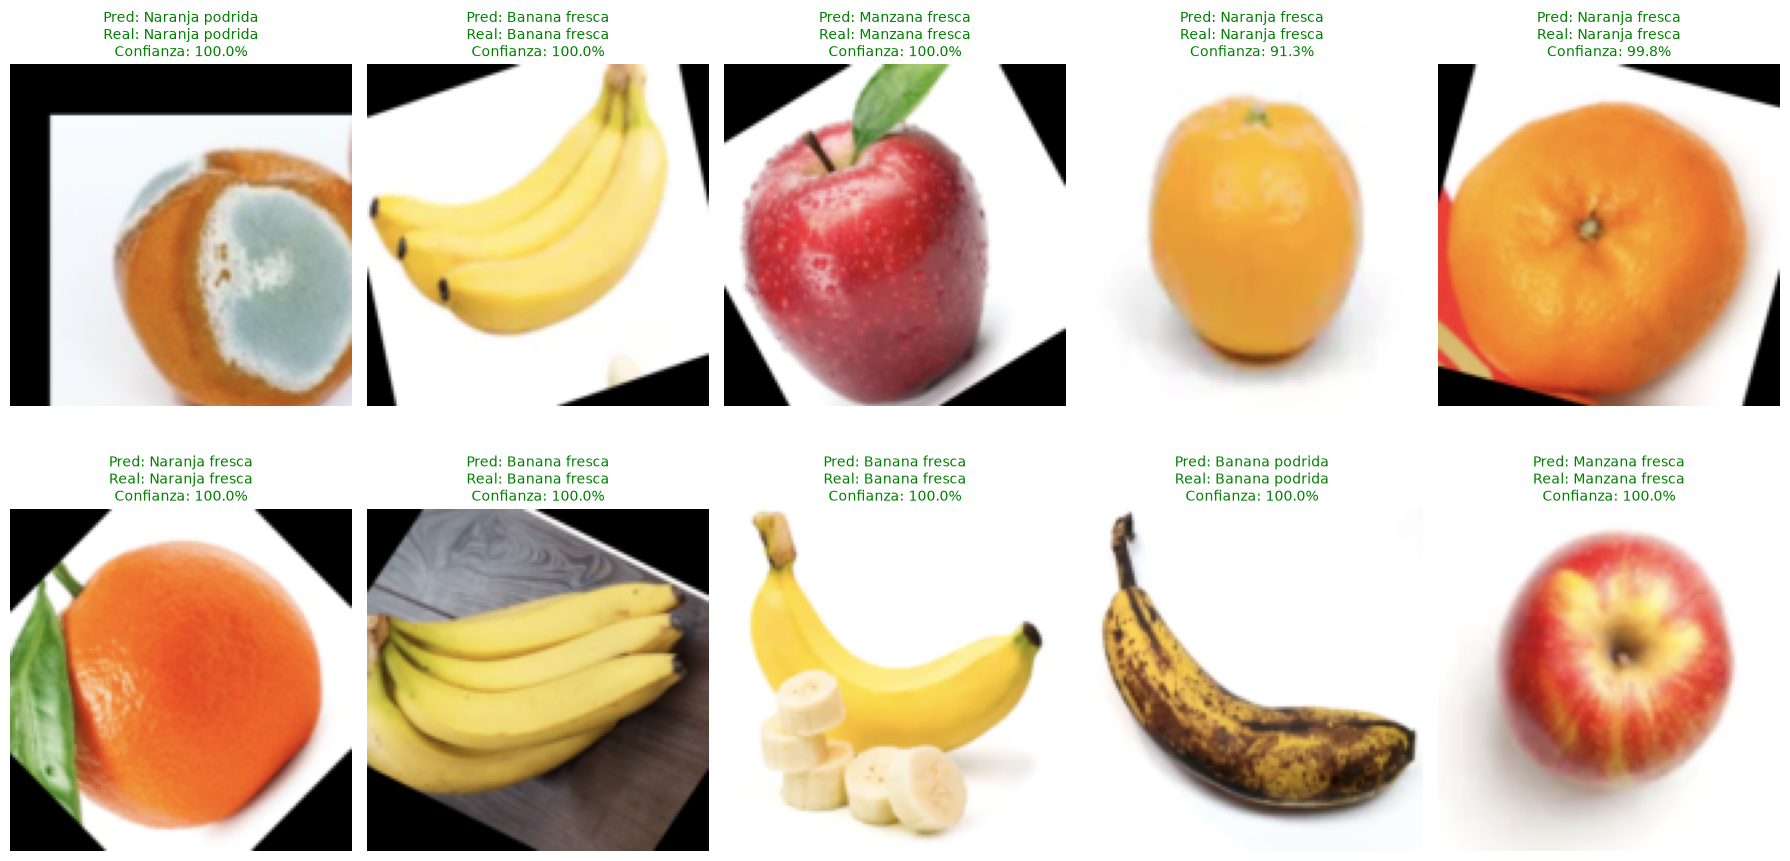

In [13]:
idx_azar = random.sample(range(len(test_dataset)), 10)  # 10 índices al azar del test, sin repetir
fig, axes = plt.subplots(2, 5, figsize=(18, 9.5))  # Cuadrícula de 2 filas x 5 columnas
for ax, idx in zip(axes.flat, idx_azar):  # Recorre cada subgráfico junto con su índice
    image, real = test_dataset[idx]  # Imagen (tensor normalizado) y su etiqueta real
    pred = all_preds[idx]  # Predicción (ya calculada en la evaluación; el orden coincide porque shuffle=False)
    conf = all_probs[idx, pred]  # Probabilidad de la clase predicha
    color = "green" if pred == real else "red"  # Verde si acierta, rojo si falla
    ax.imshow(desnormalizar(image))  # Muestra la imagen desnormalizada
    ax.set_title(f"Pred: {nombres[pred]}\nReal: {nombres[real]}\nConfianza: {conf:.1%}", color=color, fontsize=10)
    ax.axis("off")  # Sin ejes
plt.tight_layout()
plt.show()

## 12. Análisis de errores

Mirar los errores enseña más que mirar los aciertos. Mostramos las imágenes mal clasificadas y contamos cuáles son las **confusiones más frecuentes**.

Al ver los errores conviene preguntarse:
- ¿La etiqueta del dataset está bien? (A veces el error es del dataset, no del modelo.)
- ¿La fruta está en una etapa intermedia, apenas empezando a pudrirse?
- ¿Es una foto difícil (fondo raro, mucho zoom, varias frutas, mala luz)?
- ¿La red confunde **la fruta** (manzana vs naranja) o **el estado** (fresca vs podrida)?

Errores: 25 de 2698 (0.93%)

    7 veces:  real = Naranja podrida -> predicho = Manzana podrida
    6 veces:  real = Manzana podrida -> predicho = Manzana fresca
    4 veces:  real = Naranja fresca  -> predicho = Naranja podrida
    1 veces:  real = Naranja podrida -> predicho = Naranja fresca
    1 veces:  real = Naranja fresca  -> predicho = Manzana podrida
    1 veces:  real = Manzana podrida -> predicho = Naranja podrida


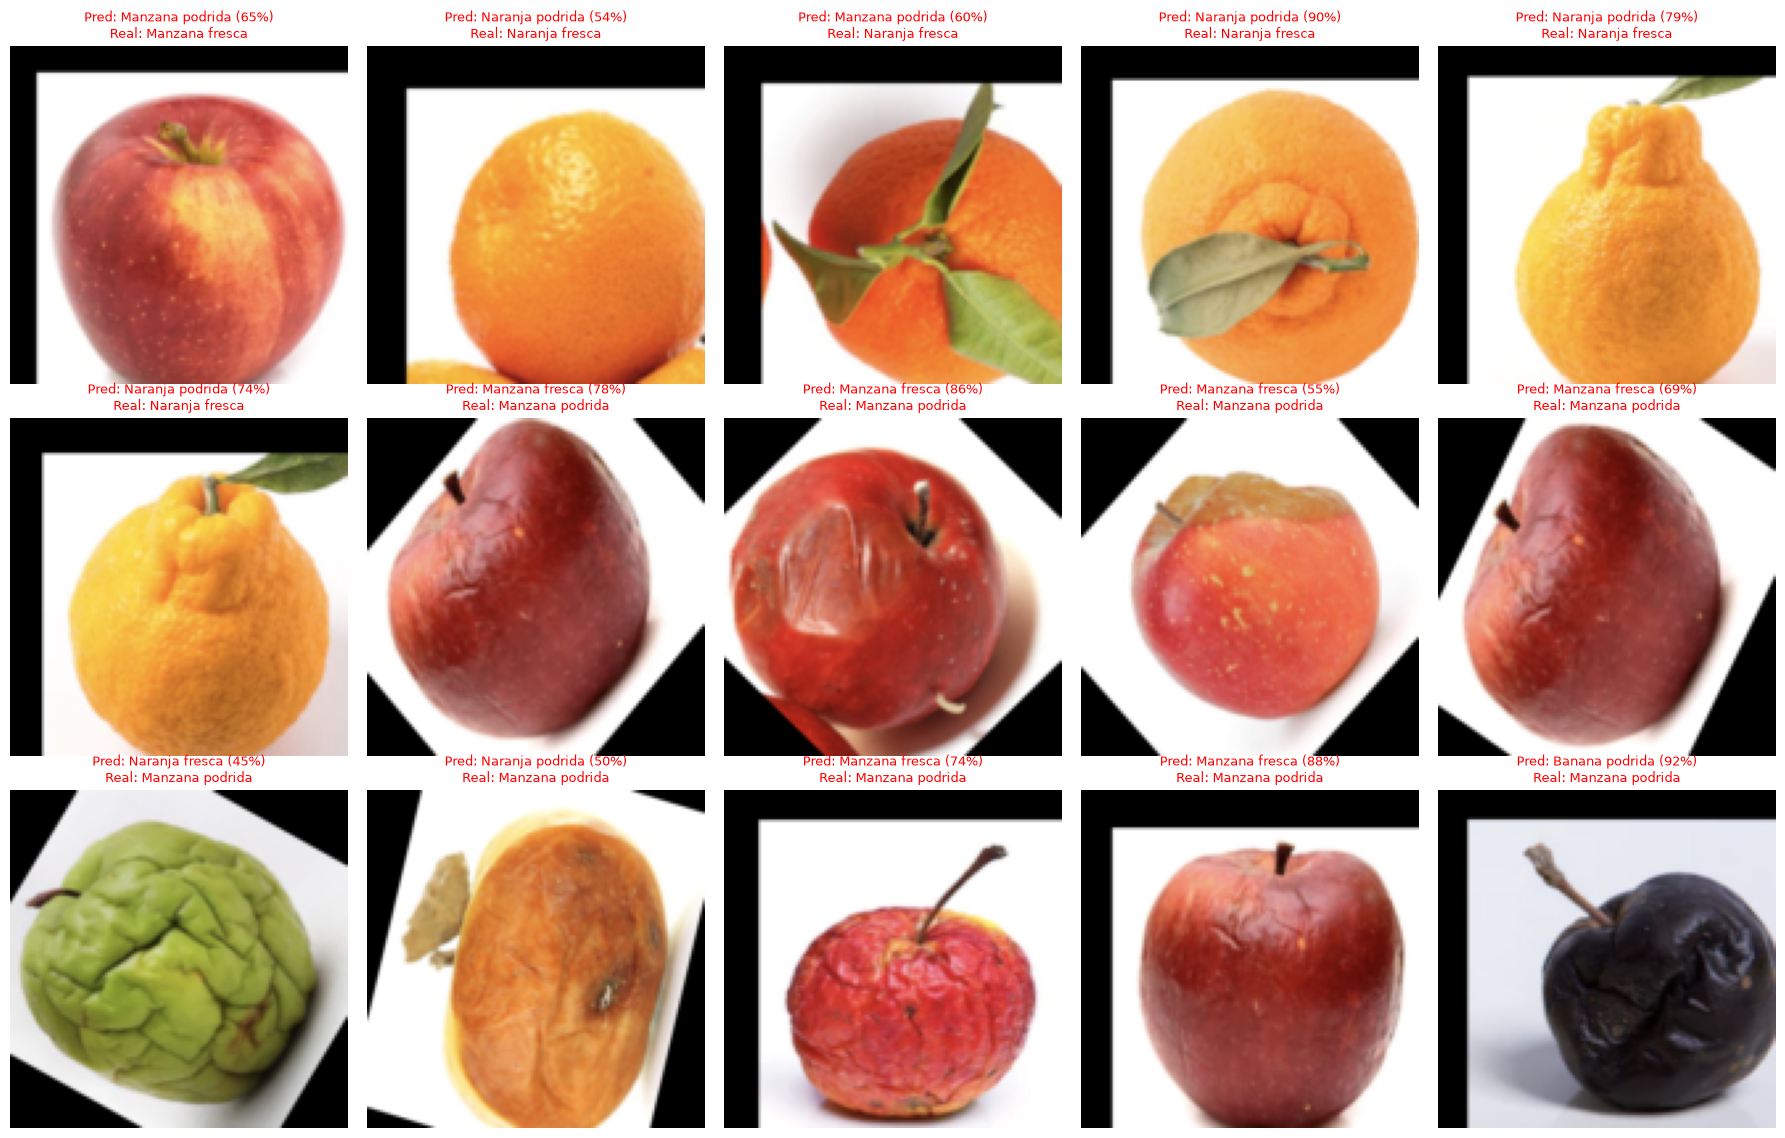

In [14]:
errores = np.where(all_preds != all_labels)[0]  # Índices del test donde la predicción no coincide con la etiqueta
print(f"Errores: {len(errores)} de {len(all_labels)} ({100 * len(errores) / len(all_labels):.2f}%)\n")

# ---- Confusiones más frecuentes (los valores fuera de la diagonal de la matriz de confusión) ----
pares = [(cm[i, j], nombres[i], nombres[j]) for i in range(len(clases)) for j in range(len(clases)) if i != j and cm[i, j] > 0]
for n, real, pred in sorted(pares, reverse=True)[:6]:  # Las 6 confusiones más comunes
    print(f"  {n:3d} veces:  real = {real:15s} -> predicho = {pred}")

# ---- Mostrar hasta 15 imágenes mal clasificadas ----
if len(errores) > 0:
    muestra = errores[:15]  # Las primeras 15 (o menos)
    filas = (len(muestra) + 4) // 5  # Cantidad de filas necesarias para 5 columnas
    fig, axes = plt.subplots(filas, 5, figsize=(18, 3.8 * filas), squeeze=False)
    for ax in axes.flat:  # Primero apagamos todos los ejes (por si sobran espacios)
        ax.axis("off")
    for ax, idx in zip(axes.flat, muestra):
        image, real = test_dataset[idx]  # Imagen y etiqueta real
        pred = all_preds[idx]  # Lo que predijo la red
        ax.imshow(desnormalizar(image))
        ax.set_title(f"Pred: {nombres[pred]} ({all_probs[idx, pred]:.0%})\nReal: {nombres[real]}", color="red", fontsize=9)
    plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / "errores_cnn.png", dpi=100)
    plt.show()

## 13. (Opcional) ¿Qué ve la CNN?

Una CNN no es una caja negra total: podemos mirar por dentro.
- **Filtros de `conv1`:** son 32 matrices de 3x3x3 aprendidas. Como tienen 3 canales, se pueden dibujar como diminutas imágenes RGB. Suelen parecerse a detectores de bordes o de colores.
- **Feature maps (mapas de activación):** son la salida de cada bloque para una imagen concreta. En `conv1` todavía se reconoce la fruta (bordes, zonas claras y oscuras); en `conv2` y `conv3` los mapas son más chicos y abstractos, porque responden a patrones más complejos (manchas, texturas).

Para obtenerlos pasamos la imagen **bloque por bloque** "a mano", igual que en `forward`.

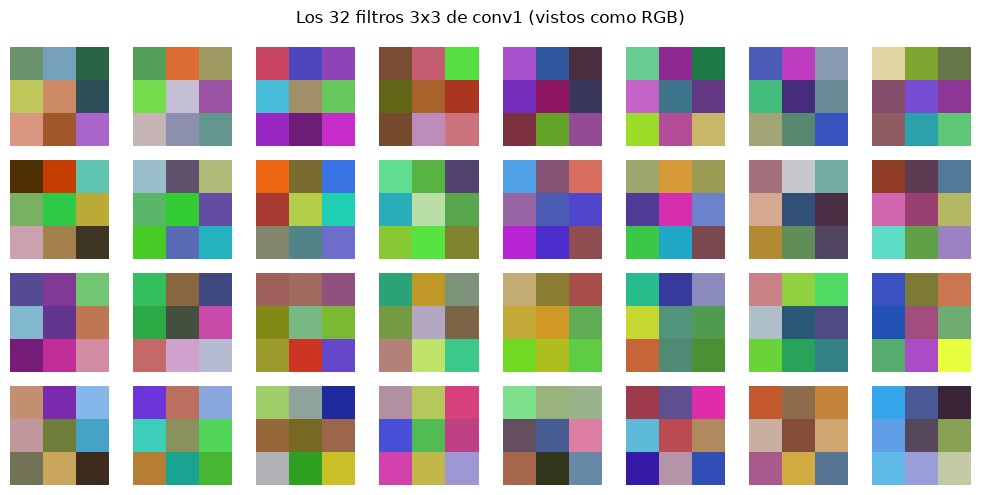

In [15]:
# ---- Filtros de conv1 ----
w = net.conv1.weight.detach().cpu()  # Pesos de conv1: forma (32, 3, 3, 3) = (filtros, canales, alto, ancho)
w = (w - w.min()) / (w.max() - w.min())  # Escalamos a [0, 1] para poder dibujarlos como imágenes
fig, axes = plt.subplots(4, 8, figsize=(10, 5))  # 32 filtros en una cuadrícula de 4x8
for i, ax in enumerate(axes.flat):
    ax.imshow(w[i].permute(1, 2, 0).numpy())  # (3, 3, 3) -> (3, 3, 3) en formato (H, W, C) para matplotlib
    ax.axis("off")
plt.suptitle("Los 32 filtros 3x3 de conv1 (vistos como RGB)")
plt.tight_layout()
plt.show()

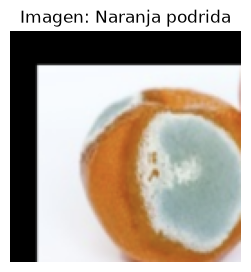

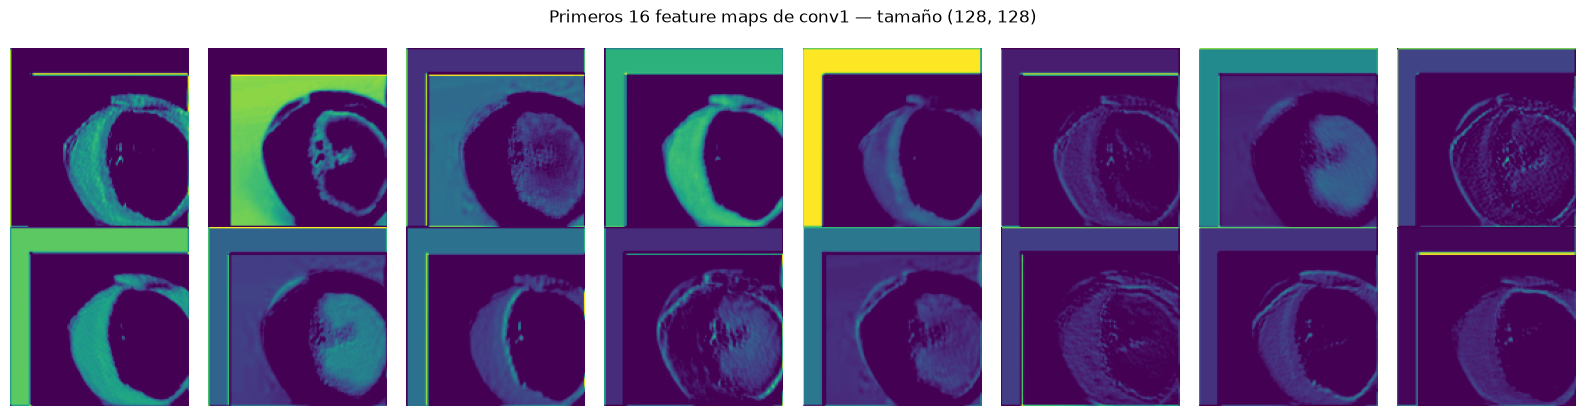

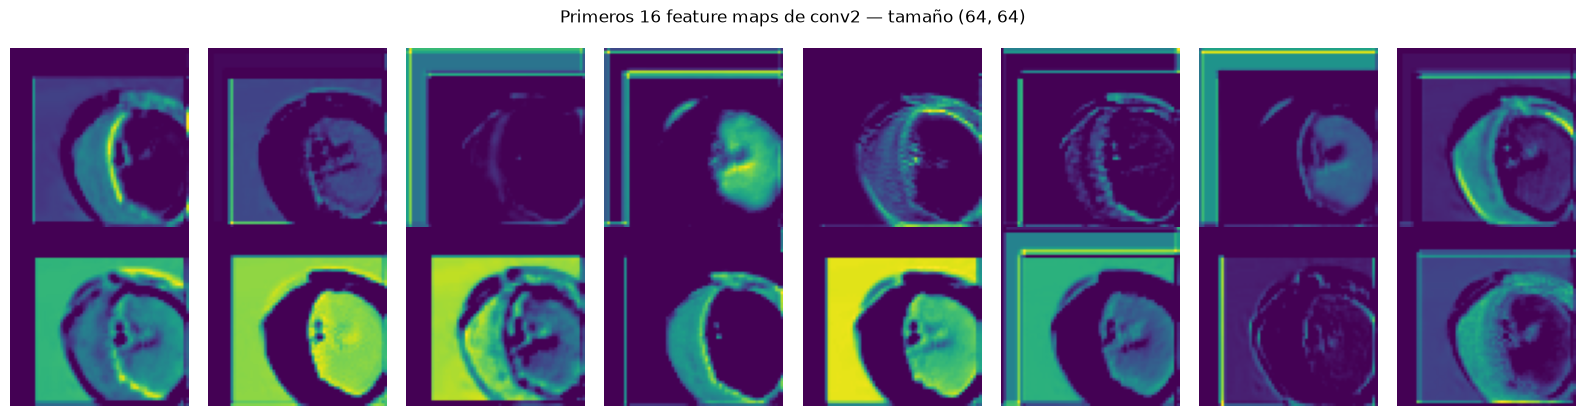

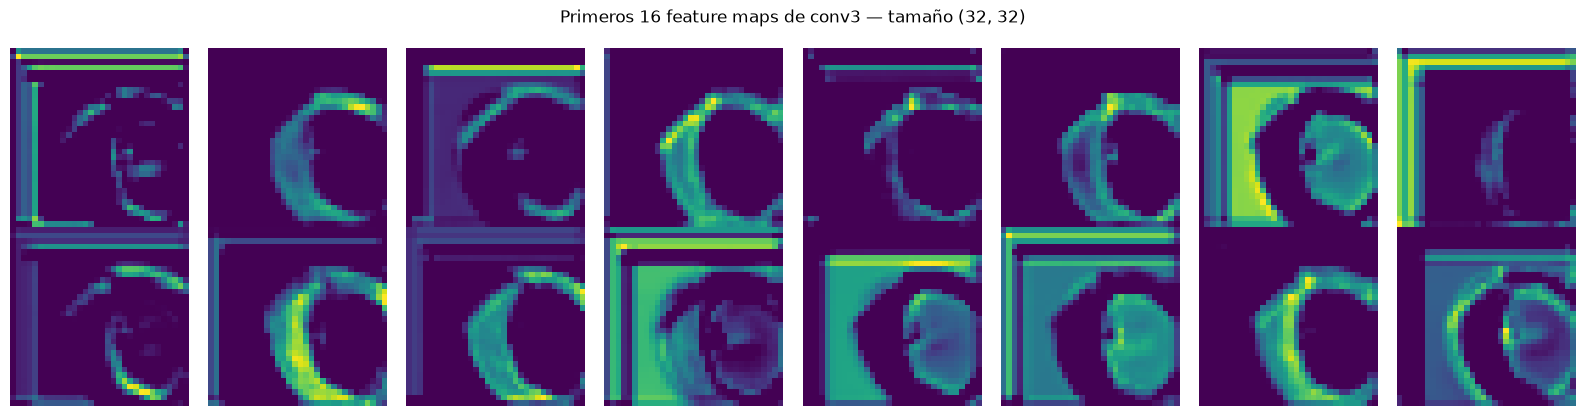

In [16]:
# ---- Feature maps de una imagen del test ----
idx = idx_azar[0]  # Tomamos una de las imágenes al azar de la sección 11
image, real = test_dataset[idx]  # Imagen normalizada y su clase real
net.eval()
with torch.no_grad():
    x = image.unsqueeze(0).to(device)  # Agrega la dimensión de batch: (1, 3, 128, 128)
    f1 = F.relu(net.bn1(net.conv1(x)))  # Salida del bloque 1 ANTES del pooling: (1, 32, 128, 128)
    f2 = F.relu(net.bn2(net.conv2(net.pool(f1))))  # Bloque 2: (1, 64, 64, 64)
    f3 = F.relu(net.bn3(net.conv3(net.pool(f2))))  # Bloque 3: (1, 128, 32, 32)

plt.figure(figsize=(3, 3))
plt.imshow(desnormalizar(image)); plt.title(f"Imagen: {nombres[real]}"); plt.axis("off")
plt.show()

for nombre_capa, fmap in [("conv1", f1), ("conv2", f2), ("conv3", f3)]:  # Para cada bloque...
    fmap = fmap[0].cpu()  # Quitamos la dimensión de batch: (canales, H, W)
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.2))  # Mostramos los primeros 16 canales
    for i, ax in enumerate(axes.flat):
        ax.imshow(fmap[i].numpy(), cmap="viridis")  # Cada canal es un mapa en escala de intensidad
        ax.axis("off")
    plt.suptitle(f"Primeros 16 feature maps de {nombre_capa} — tamaño {tuple(fmap.shape[1:])}")
    plt.tight_layout()
    plt.show()

## 14. Predicción con fotos propias

La prueba de fuego: fotos **tomadas por nosotros** (con el celular, en el mercado o en la casa) que la red nunca vio. Hay que ponerlas en la carpeta `imagenes_prueba/` (jpg, png o webp).

Pasos para predecir una imagen nueva:
1. Abrirla y convertirla a RGB. `exif_transpose` corrige la rotación de las fotos del celular, que vienen giradas según el sensor.
2. Aplicarle **exactamente** el mismo `test_transform` (resize, tensor y normalize).
3. Agregarle la dimensión de batch con `unsqueeze(0)`, pasarla por la red y aplicar softmax.

Es normal que acierte **menos** que en el test: las fotos del dataset tienen un estilo particular (fondos, iluminación) y las nuestras son distintas. A esto se le llama ***domain shift***.

In [17]:
def predecir_imagen(ruta):
    """Abre una imagen, la preprocesa como el test y devuelve las probabilidades de las 6 clases."""
    img = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")  # Abre, corrige la orientación y asegura 3 canales
    x = test_transform(img).unsqueeze(0).to(device)  # Mismo preprocesamiento que el test + dimensión de batch
    net.eval()
    with torch.no_grad():
        probs = torch.softmax(net(x), dim=1)[0].cpu().numpy()  # Probabilidades de las 6 clases
    return img, probs

CARPETA_PRUEBA = RAIZ / "imagenes_prueba"  # Carpeta con fotos propias
fotos = sorted(p for p in CARPETA_PRUEBA.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})

if not fotos:  # Si la carpeta está vacía
    print("No hay fotos en imagenes_prueba/. Toma fotos de manzanas, bananas o naranjas (frescas y podridas), "
          "ponlas en esa carpeta y vuelve a ejecutar esta celda.")
else:
    columnas = min(len(fotos), 4)  # Hasta 4 fotos por fila
    filas = (len(fotos) + columnas - 1) // columnas
    fig, axes = plt.subplots(filas, columnas, figsize=(4.5 * columnas, 5 * filas), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, ruta in zip(axes.flat, fotos):
        img, probs = predecir_imagen(ruta)  # Predice
        top = probs.argmax()  # Clase más probable
        veredicto = "DESCARTAR" if clases[top].startswith("rotten") else "APTA PARA VENTA"  # Decisión de control de calidad
        ax.imshow(img)
        ax.set_title(f"{ruta.name}\n{nombres[top]} ({probs[top]:.1%})\n{veredicto}",
                     color="red" if veredicto == "DESCARTAR" else "green", fontsize=10)
    plt.tight_layout()
    plt.show()

No hay fotos en imagenes_prueba/. Toma fotos de manzanas, bananas o naranjas (frescas y podridas), ponlas en esa carpeta y vuelve a ejecutar esta celda.


## 15. Guardar el modelo

Guardamos el **`state_dict`**, un diccionario con todos los pesos aprendidos, y **no** el objeto completo. Para cargarlo después se crea una `Net()` y se le cargan los pesos; por eso guardamos la clase en `src/modelo.py`.

En `config.json` dejamos todo lo que la app necesita para preprocesar igual que en el entrenamiento: el orden de las clases (sale de `ImageFolder.classes`, **no** se escribe a mano), el tamaño y la normalización. También guardamos las métricas reales en `outputs/metricas_cnn.json` para la tabla comparativa con ResNet18.

In [18]:
if QUICK_RUN:  # En modo prueba no sobrescribimos el modelo bueno
    print("QUICK_RUN: el modelo NO se guarda (para no pisar el modelo del entrenamiento completo).")
else:
    ruta_pesos = MODELS_DIR / "frutas_cnn.pth"
    torch.save(net.state_dict(), ruta_pesos)  # Guarda solo los pesos (el state_dict del mejor epoch)

    config = {
        "modelo": "Net",  # Nombre de la clase en src/modelo.py
        "img_size": IMG_SIZE,  # Tamaño de entrada
        "mean": list(MEAN),  # Normalización (tiene que ser la misma al predecir)
        "std": list(STD),
        "clases": clases,  # Orden de las clases = índice de salida de la red (sale de ImageFolder)
        "nombres_es": {c: NOMBRES_ES[c] for c in clases},  # Nombres en español
    }
    (MODELS_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

    metricas = {
        "modelo": "CNN propia (Net)",
        "test_accuracy": round(float(accuracy), 4),  # Accuracy real en test
        "mejor_val_accuracy": round(float(mejor_acc), 4),
        "mejor_epoch": mejor_epoch,
        "epochs": N_EPOCHS,
        "parametros": n_total,
        "tamano_mb": round(ruta_pesos.stat().st_size / 1e6, 1),  # Tamaño del archivo .pth en MB
        "tiempo_entrenamiento_s": round(tiempo_entrenamiento, 1),
    }
    (OUTPUTS_DIR / "metricas_cnn.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")

    print(f"Modelo guardado en {ruta_pesos} ({metricas['tamano_mb']} MB)")
    print("Config guardado en", MODELS_DIR / "config.json")
    print(json.dumps(metricas, indent=2, ensure_ascii=False))

Modelo guardado en ..\models\frutas_cnn.pth (67.5 MB)
Config guardado en ..\models\config.json
{
  "modelo": "CNN propia (Net)",
  "test_accuracy": 0.9907,
  "mejor_val_accuracy": 0.9933,
  "mejor_epoch": 20,
  "epochs": 20,
  "parametros": 16875526,
  "tamano_mb": 67.5,
  "tiempo_entrenamiento_s": 180.6
}


## 16. Respuestas a las preguntas del assignment

**1. ¿Qué learning rate usa el optimizador?**
`0.001`. Aunque el enunciado del maestro dice "SGD", su código usa **Adam** con `lr=0.001`, y nosotros también.

**2. ¿Qué valor de momentum usa el optimizador?**
Adam no tiene un parámetro `momentum` como SGD, pero tiene un equivalente: `betas=(0.9, 0.999)` (valores por defecto). El `0.9` es el "momentum": cada paso es un promedio que recuerda ~90% de la dirección anterior.

**3. ¿Qué batch size se usa en el DataLoader de entrenamiento?**
`64` (el maestro usa 32). Con la GPU de 8 GB entra sin problema y cada epoch tiene la mitad de pasos.

**4. ¿Cuántos epochs se entrena la red?**
`20`. Además guardamos el **mejor** epoch según la validación (ver la sección 8).

**5. ¿Cómo se definen los números de filtros de las capas convolucionales?**
`32 → 64 → 128`: se **duplican** en cada bloque. Como cada MaxPool reduce el ancho y el alto a la mitad, se compensa con más filtros: la red pierde resolución espacial pero gana "variedad" de patrones detectados, que además son más complejos en las capas profundas.

**6. ¿A qué tamaño se redimensionan las imágenes?**
`128 x 128` píxeles.

**7. ¿Qué parámetros de normalización (media y desviación estándar) se usan?**
`mean = (0.5, 0.5, 0.5)` y `std = (0.5, 0.5, 0.5)` por canal. Así los píxeles pasan de [0, 1] a **[-1, 1]**.

**8. ¿Qué tamaño de kernel usa cada capa convolucional?**
`3 x 3` con `padding=1` en las tres capas (así se mantiene el tamaño espacial antes del pooling).

**9. ¿Cuál es la accuracy del modelo?**
Es la que se imprime en la celda de abajo, calculada en el **test** con el mejor modelo.

**10. ¿Cómo mejorar la accuracy?**
- **Transfer learning** (por ejemplo, ResNet18 preentrenada en ImageNet): reutiliza filtros aprendidos con millones de imágenes. Es lo que hacemos en el notebook `02`.
- Reemplazar el `fc1` gigante (16.8M parámetros) por **`AdaptiveAvgPool2d`** + una capa pequeña: muchísimos menos parámetros y menos overfitting.
- **Más augmentation** (zoom/recorte aleatorio, más rotación) y **más epochs con un scheduler** que baje el learning rate de a poco.
- **Imágenes más grandes** (por ejemplo, 224x224) para ver mejor los detalles de las manchas.
- **Más bloques convolucionales**, o datos más variados (fotos reales de mercado).

In [19]:
print(f"Accuracy en TEST:          {accuracy * 100:.2f}%")  # Respuesta a la pregunta 9 (valor real)
print(f"Mejor accuracy validación: {mejor_acc * 100:.2f}% (epoch {mejor_epoch} de {N_EPOCHS})")
print(f"Tiempo de entrenamiento:   {tiempo_entrenamiento / 60:.1f} min en {device}")
print(f"Parámetros del modelo:     {n_total:,}")

Accuracy en TEST:          99.07%
Mejor accuracy validación: 99.33% (epoch 20 de 20)
Tiempo de entrenamiento:   3.0 min en cuda
Parámetros del modelo:     16,875,526


## 17. Conclusiones

Resultados del entrenamiento completo (20 epochs, RTX 4070 Laptop):

| Métrica | Valor |
|---|---|
| Accuracy en **test** | **99.07%** (2,673 de 2,698; 25 errores) |
| Mejor accuracy en validación | 99.33% (epoch 20) |
| Tiempo de entrenamiento | 3.0 min (~7.5 s por epoch en GPU) |
| Parámetros | 16,875,526 (99.4% en `fc1`) |
| Tamaño del modelo (`.pth`) | 67.5 MB |

1. **La CNN del maestro, adaptada a 6 clases, aprende muy bien el problema:** el F1 está entre 0.984 y 0.999 en todas las clases. Las clases más fáciles son las bananas, y donde más se equivoca es entre **manzana podrida y naranja podrida**, y entre **manzana podrida y manzana fresca**.
2. **No se ve overfitting en las curvas:** la loss de train y la de validación bajan juntas, y el mejor epoch fue el último. Esto sugiere que con más epochs (y un scheduler) todavía podría mejorar un poco.
3. **La GPU hace una gran diferencia:** 20 epochs en 3 minutos. El primer epoch tarda más (~38 s) porque arranca los procesos de carga y CUDA.
4. **El 99% es optimista:** el test contiene versiones rotadas o volteadas de fotos que también están en train (*data leakage*, ver la sección 4). La medida honesta de cómo funciona "en la vida real" es la prueba con **fotos propias** (sección 14).
5. **El punto débil de la arquitectura es `fc1`:** con 16.8M parámetros es casi todo el modelo. Para mejorar: transfer learning (notebook 02), `AdaptiveAvgPool2d`, más augmentation y más datos reales.